In [1]:
# ============================================================
# EXPERIMENT NO. 9
# Comparison of SVM Kernels on Fashion MNIST
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

In [2]:
# ============================================================
# Step 1: Load Fashion MNIST Dataset
# ============================================================

df = pd.read_csv(
    "D:/26-27/ODD/lab/Dataset/fashion-mnist_train.csv"
)

print("Fashion MNIST Dataset:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

Fashion MNIST Dataset:
   label  pixel1  pixel2  pixel3  pixel4  pixel5  pixel6  pixel7  pixel8  \
0      2       0       0       0       0       0       0       0       0   
1      9       0       0       0       0       0       0       0       0   
2      6       0       0       0       0       0       0       0       5   
3      0       0       0       0       1       2       0       0       0   
4      3       0       0       0       0       0       0       0       0   

   pixel9  ...  pixel775  pixel776  pixel777  pixel778  pixel779  pixel780  \
0       0  ...         0         0         0         0         0         0   
1       0  ...         0         0         0         0         0         0   
2       0  ...         0         0         0        30        43         0   
3       0  ...         3         0         0         0         0         1   
4       0  ...         0         0         0         0         0         0   

   pixel781  pixel782  pixel783  pixel784  
0      

In [3]:
# Select first 5000 samples
df = df.iloc[:5000, :]

# Label
y = df.iloc[:, 0].values

# Pixel features
X = df.iloc[:, 1:].values

# Normalize
X = X / 255.0

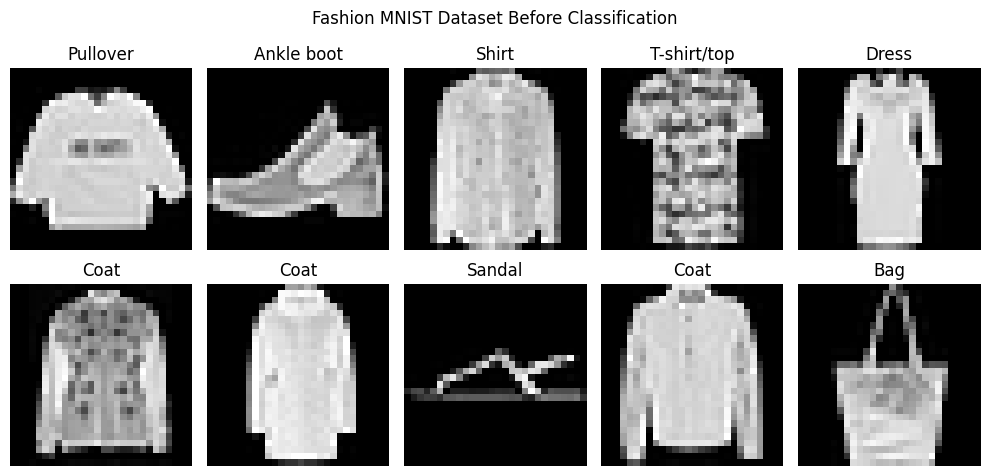

In [4]:
# ============================================================
# Step 3: Display Dataset BEFORE Classification
# ============================================================

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

plt.figure(figsize=(10, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X[i].reshape(28, 28),
        cmap="gray"
    )

    plt.title(class_names[y[i]])
    plt.axis("off")

plt.suptitle("Fashion MNIST Dataset Before Classification")

plt.tight_layout()

plt.show()

In [5]:
# ============================================================
# Step 4: Normalize Pixel Values
# ============================================================

X = X / 255.0

In [6]:
X = X[:5000]
y = y[:5000]

In [7]:
# ============================================================
# Step 5: Split Dataset
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:", X_train.shape)
print("Testing Data Shape :", X_test.shape)


Training Data Shape: (4000, 784)
Testing Data Shape : (1000, 784)


In [8]:
# ============================================================
# Step 6: Linear SVM
# ============================================================

print("\nTraining Linear SVM...")

linear_svm = SVC(
    kernel="linear",
    C=1
)

linear_svm.fit(
    X_train,
    y_train
)

y_pred_linear = linear_svm.predict(
    X_test
)

linear_accuracy = accuracy_score(
    y_test,
    y_pred_linear
)

print(
    "Linear SVM Accuracy:",
    linear_accuracy * 100,
    "%"
)


Training Linear SVM...
Linear SVM Accuracy: 10.299999999999999 %


In [9]:
# ============================================================
# Step 7: Polynomial SVM
# ============================================================

print("\nTraining Polynomial SVM...")

poly_svm = SVC(
    kernel="poly",
    degree=3,
    C=1
)

poly_svm.fit(
    X_train,
    y_train
)

y_pred_poly = poly_svm.predict(
    X_test
)

poly_accuracy = accuracy_score(
    y_test,
    y_pred_poly
)

print(
    "Polynomial SVM Accuracy:",
    poly_accuracy * 100,
    "%"
)


Training Polynomial SVM...
Polynomial SVM Accuracy: 79.3 %


In [10]:
# ============================================================
# Step 8: RBF SVM
# ============================================================

print("\nTraining RBF SVM...")

rbf_svm = SVC(
    kernel="rbf",
    C=1,
    gamma="scale"
)

rbf_svm.fit(
    X_train,
    y_train
)

y_pred_rbf = rbf_svm.predict(
    X_test
)

rbf_accuracy = accuracy_score(
    y_test,
    y_pred_rbf
)

print(
    "RBF SVM Accuracy:",
    rbf_accuracy * 100,
    "%"
)


Training RBF SVM...
RBF SVM Accuracy: 84.6 %


In [11]:
# ============================================================
# Step 9: Compare Performance
# ============================================================

print("\n======================================")
print("SVM PERFORMANCE COMPARISON")
print("======================================")

print(
    "Linear Kernel     :",
    linear_accuracy * 100,
    "%"
)

print(
    "Polynomial Kernel :",
    poly_accuracy * 100,
    "%"
)

print(
    "RBF Kernel        :",
    rbf_accuracy * 100,
    "%"
)


SVM PERFORMANCE COMPARISON
Linear Kernel     : 10.299999999999999 %
Polynomial Kernel : 79.3 %
RBF Kernel        : 84.6 %


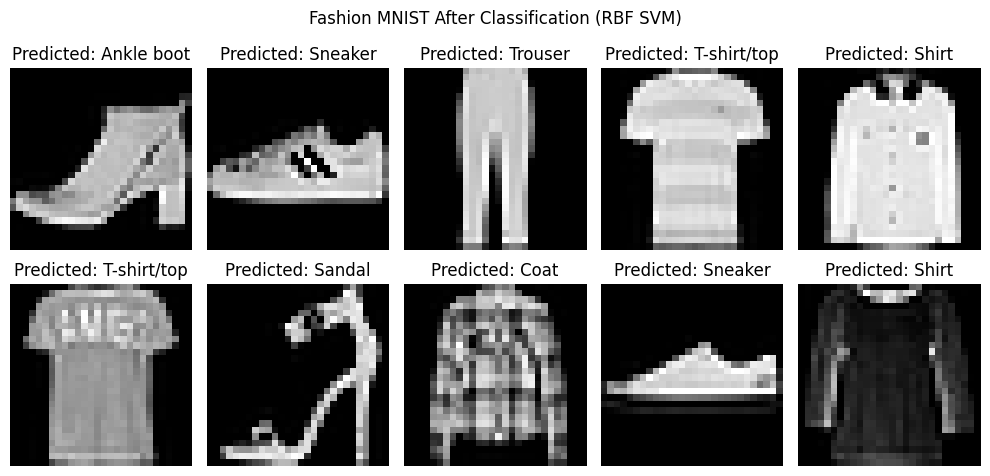

In [13]:
# ============================================================
# Step 11: Display Dataset AFTER Classification
# ============================================================

# Display some test images with predicted classes

plt.figure(figsize=(10, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(
        X_test[i].reshape(28, 28),
        cmap="gray"
    )

    plt.title(
        "Predicted: " +
        class_names[y_pred_rbf[i]]
    )

    plt.axis("off")

plt.suptitle(
    "Fashion MNIST After Classification (RBF SVM)"
)

plt.tight_layout()

plt.show()

In [14]:
# ============================================================
# Step 12: Display Actual vs Predicted Classes
# ============================================================

print("\n======================================")
print("ACTUAL VS PREDICTED")
print("======================================")

for i in range(20):

    print(
        "Image", i + 1,
        ": Actual =",
        class_names[y_test[i]],
        ", Predicted =",
        class_names[y_pred_rbf[i]]
    )


ACTUAL VS PREDICTED
Image 1 : Actual = Ankle boot , Predicted = Ankle boot
Image 2 : Actual = Sneaker , Predicted = Sneaker
Image 3 : Actual = Trouser , Predicted = Trouser
Image 4 : Actual = T-shirt/top , Predicted = T-shirt/top
Image 5 : Actual = Coat , Predicted = Shirt
Image 6 : Actual = T-shirt/top , Predicted = T-shirt/top
Image 7 : Actual = Sandal , Predicted = Sandal
Image 8 : Actual = Shirt , Predicted = Coat
Image 9 : Actual = Sneaker , Predicted = Sneaker
Image 10 : Actual = Shirt , Predicted = Shirt
Image 11 : Actual = Ankle boot , Predicted = Ankle boot
Image 12 : Actual = Shirt , Predicted = T-shirt/top
Image 13 : Actual = Trouser , Predicted = Trouser
Image 14 : Actual = Shirt , Predicted = Dress
Image 15 : Actual = Sandal , Predicted = Sandal
Image 16 : Actual = Trouser , Predicted = Trouser
Image 17 : Actual = Dress , Predicted = Dress
Image 18 : Actual = Dress , Predicted = Dress
Image 19 : Actual = Pullover , Predicted = Pullover
Image 20 : Actual = T-shirt/top , Pr